In [1]:
# ============================================================
# LoveDA Dataset Verification - Split-Aware Version
# ============================================================

from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# ============================================================
# SET DATASET PATH
# ============================================================

DATASET_DIR = Path("LoveDA")

if not DATASET_DIR.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATASET_DIR}\n"
        "Change DATASET_DIR to the location of your LoveDA folder."
    )

print("Dataset found:", DATASET_DIR.resolve())

Dataset found: C:\Users\CUTM\Desktop\Remote-Sensing-Semantic-Segmentation\LoveDA


In [3]:
# ============================================================
# 1. DATASET FOLDER STRUCTURE
# ============================================================

def print_folder_structure(folder, max_depth=4, depth=0):
    folder = Path(folder)
    if depth > max_depth:
        return
    indent = "    " * depth
    if depth == 0:
        print(f"📁 {folder.name}/")
    try:
        items = sorted(folder.iterdir(), key=lambda x: (x.is_file(), x.name.lower()))
    except PermissionError:
        print(indent + "[Permission denied]")
        return
    for item in items:
        if item.is_dir():
            print(f"{indent}📁 {item.name}/")
            print_folder_structure(item, max_depth, depth + 1)
        else:
            print(f"{indent}📄 {item.name}")

print_folder_structure(DATASET_DIR)

📁 LoveDA/
📁 Test/
    📁 Test/
        📁 Rural/
            📁 images_png/
                📄 4191.png
                📄 4192.png
                📄 4193.png
                📄 4194.png
                📄 4195.png
                📄 4196.png
                📄 4197.png
                📄 4198.png
                📄 4199.png
                📄 4200.png
                📄 4201.png
                📄 4202.png
                📄 4203.png
                📄 4204.png
                📄 4205.png
                📄 4206.png
                📄 4207.png
                📄 4208.png
                📄 4209.png
                📄 4210.png
                📄 4211.png
                📄 4212.png
                📄 4213.png
                📄 4214.png
                📄 4215.png
                📄 4216.png
                📄 4217.png
                📄 4218.png
                📄 4219.png
                📄 4220.png
                📄 4221.png
                📄 4222.png
                📄 4223.png
                📄 4224.png
         

In [4]:
# ============================================================
# 2. FIND TRAIN / VAL / TEST IMAGE AND MASK FILES
# ============================================================

IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}

def collect_files(split, kind):
    # Handles the nested structure in your downloaded dataset:
    # LoveDA/Train/Train/Rural/... and LoveDA/Val/Val/Rural/...
    split_root = DATASET_DIR / split
    if not split_root.exists():
        return []

    files = []
    for p in split_root.rglob("*"):
        if not p.is_file() or p.suffix.lower() not in IMAGE_EXTENSIONS:
            continue
        path_text = str(p).lower()
        if kind == "mask" and "masks_png" in path_text:
            files.append(p)
        elif kind == "image" and "images_png" in path_text:
            files.append(p)
    return sorted(files)

train_images = collect_files("Train", "image")
train_masks  = collect_files("Train", "mask")
val_images   = collect_files("Val", "image")
val_masks    = collect_files("Val", "mask")
test_images  = collect_files("Test", "image")
test_masks   = collect_files("Test", "mask")

print("TRAIN  images:", len(train_images), " masks:", len(train_masks))
print("VAL    images:", len(val_images),   " masks:", len(val_masks))
print("TEST   images:", len(test_images),  " masks:", len(test_masks), "(test masks are normally not provided)")

TRAIN  images: 2522  masks: 2522
VAL    images: 1669  masks: 1669
TEST   images: 1796  masks: 0 (test masks are normally not provided)


In [5]:
# ============================================================
# 3. IMAGE-MASK FILENAME MATCHING
# ============================================================

def filename_map(files):
    return {p.stem.lower(): p for p in files}

def check_matching(images, masks):
    image_map = filename_map(images)
    mask_map = filename_map(masks)
    image_names = set(image_map)
    mask_names = set(mask_map)
    return image_map, mask_map, image_names & mask_names, image_names - mask_names, mask_names - image_names

train_img_map, train_mask_map, train_match, train_img_only, train_mask_only = check_matching(train_images, train_masks)
val_img_map, val_mask_map, val_match, val_img_only, val_mask_only = check_matching(val_images, val_masks)
test_img_map = filename_map(test_images)
test_mask_map = filename_map(test_masks)

print("TRAIN:")
print("  matched:", len(train_match), "images without masks:", len(train_img_only), "masks without images:", len(train_mask_only))
print("VAL:")
print("  matched:", len(val_match), "images without masks:", len(val_img_only), "masks without images:", len(val_mask_only))
print("TEST:")
print("  images:", len(test_images), "masks:", len(test_masks))

print("\nNote: Test images without masks are NOT treated as an error because the official LoveDA workflow uses Train/Validation for development and submits test predictions for evaluation.")

TRAIN:
  matched: 2522 images without masks: 0 masks without images: 0
VAL:
  matched: 1669 images without masks: 0 masks without images: 0
TEST:
  images: 1796 masks: 0

Note: Test images without masks are NOT treated as an error because the official LoveDA workflow uses Train/Validation for development and submits test predictions for evaluation.


In [6]:
# ============================================================
# 4. IMAGE AND MASK DIMENSIONS + CORRUPTION CHECK
# ============================================================

def inspect_files(files):
    sizes = Counter()
    corrupted = []
    for p in files:
        try:
            with Image.open(p) as img:
                img.verify()
            with Image.open(p) as img:
                sizes[img.size] += 1
        except Exception as e:
            corrupted.append((str(p), str(e)))
    return sizes, corrupted

train_img_sizes, train_img_corrupt = inspect_files(train_images)
val_img_sizes, val_img_corrupt = inspect_files(val_images)
test_img_sizes, test_img_corrupt = inspect_files(test_images)
train_mask_sizes, train_mask_corrupt = inspect_files(train_masks)
val_mask_sizes, val_mask_corrupt = inspect_files(val_masks)

print("TRAIN image dimensions:", train_img_sizes)
print("VAL image dimensions:", val_img_sizes)
print("TEST image dimensions:", test_img_sizes)
print("TRAIN mask dimensions:", train_mask_sizes)
print("VAL mask dimensions:", val_mask_sizes)
print("Corrupted images:", len(train_img_corrupt) + len(val_img_corrupt) + len(test_img_corrupt))
print("Corrupted masks:", len(train_mask_corrupt) + len(val_mask_corrupt))

TRAIN image dimensions: Counter({(1024, 1024): 2522})
VAL image dimensions: Counter({(1024, 1024): 1669})
TEST image dimensions: Counter({(1024, 1024): 1796})
TRAIN mask dimensions: Counter({(1024, 1024): 2522})
VAL mask dimensions: Counter({(1024, 1024): 1669})
Corrupted images: 0
Corrupted masks: 0


In [7]:
# ============================================================
# 5. CHECK IMAGE-MASK DIMENSIONS FOR ALL SUPERVISED PAIRS
# ============================================================

def find_dimension_mismatches(image_map, mask_map, matches):
    mismatches = []
    for name in sorted(matches):
        try:
            with Image.open(image_map[name]) as img:
                image_size = img.size
            with Image.open(mask_map[name]) as mask:
                mask_size = mask.size
            if image_size != mask_size:
                mismatches.append({"filename": name, "image_size": image_size, "mask_size": mask_size})
        except Exception as e:
            mismatches.append({"filename": name, "image_size": "ERROR", "mask_size": str(e)})
    return mismatches

train_dim_mismatch = find_dimension_mismatches(train_img_map, train_mask_map, train_match)
val_dim_mismatch = find_dimension_mismatches(val_img_map, val_mask_map, val_match)

print("TRAIN image-mask dimension mismatches:", len(train_dim_mismatch))
print("VAL image-mask dimension mismatches:", len(val_dim_mismatch))

TRAIN image-mask dimension mismatches: 0
VAL image-mask dimension mismatches: 0


In [8]:
# ============================================================
# 6. UNIQUE MASK CLASS IDS
# ============================================================

def get_class_counts(mask_files):
    class_counts = Counter()
    for p in mask_files:
        try:
            with Image.open(p) as mask:
                arr = np.array(mask)
            values, counts = np.unique(arr, return_counts=True)
            for v, c in zip(values, counts):
                class_counts[int(v)] += int(c)
        except Exception as e:
            print("Error reading:", p, e)
    return class_counts

class_counts = get_class_counts(train_masks + val_masks)
class_ids = sorted(class_counts.keys())

print("Unique raw mask IDs:", class_ids)
print("Number of raw IDs:", len(class_ids))

# LoveDA's official repository states that 0 is no-data/ignore and 1-7 are the seven land-cover categories.
# We preserve the raw IDs here; label remapping will be done later during preprocessing.
CLASS_NAMES = {
    0: "No-data / Ignore",
    1: "Background",
    2: "Building",
    3: "Road",
    4: "Water",
    5: "Barren",
    6: "Forest",
    7: "Agriculture",
}

class_table = pd.DataFrame({
    "Raw_ID": class_ids,
    "Class_Name": [CLASS_NAMES.get(i, "Unknown") for i in class_ids],
    "Pixel_Count": [class_counts[i] for i in class_ids]
})
class_table["Percentage"] = class_table["Pixel_Count"] / class_table["Pixel_Count"].sum() * 100
display(class_table)

Unique raw mask IDs: [0, 1, 2, 3, 4, 5, 6, 7]
Number of raw IDs: 8


,Raw_ID,Class_Name,Pixel_Count,Percentage
0,0,No-data / Ignore,145409132,3.308827
1,1,Background,1525959012,34.723644
2,2,Building,404299316,9.199949
3,3,Road,213710339,4.863041
4,4,Water,362297559,8.244187
5,5,Barren,207131990,4.713349
6,6,Forest,534690631,12.167042
7,7,Agriculture,1001084037,22.779960


In [9]:
# ============================================================
# 7. VISUALIZE IMAGE + GROUND-TRUTH MASK
# ============================================================

all_pairs = []
for name in sorted(train_match):
    all_pairs.append((name, train_img_map[name], train_mask_map[name], "Train"))
for name in sorted(val_match):
    all_pairs.append((name, val_img_map[name], val_mask_map[name], "Val"))

if not all_pairs:
    raise RuntimeError("No image-mask pairs were found in Train/Val.")

name, image_path, mask_path, split = all_pairs[0]
image = np.array(Image.open(image_path).convert("RGB"))
mask = np.array(Image.open(mask_path))

print("Split:", split)
print("Sample:", name)
print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("Mask IDs in sample:", sorted(np.unique(mask).tolist()))

Split: Train
Sample: 0
Image shape: (1024, 1024, 3)
Mask shape: (1024, 1024)
Mask IDs in sample: [1, 2, 3, 4, 7]


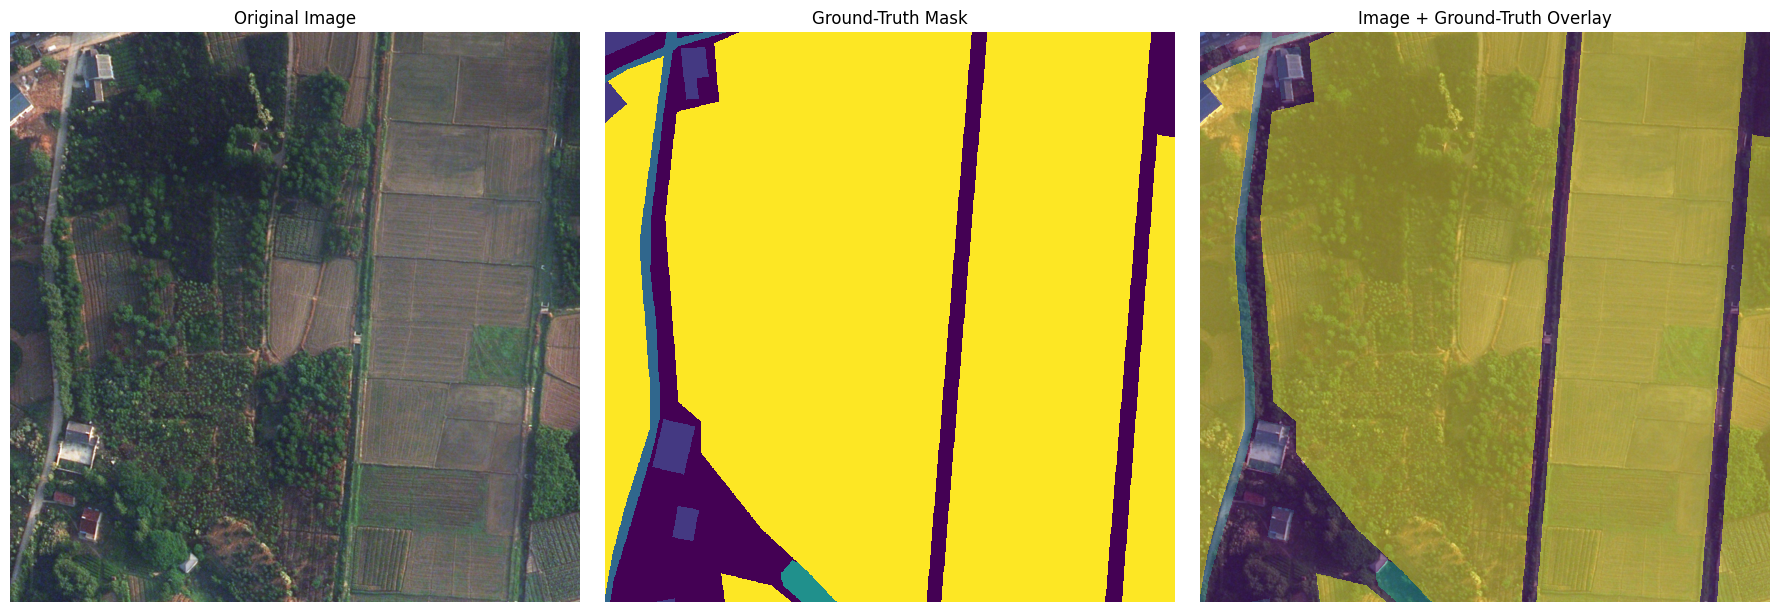

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(image)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(mask, interpolation="nearest")
axes[1].set_title("Ground-Truth Mask")
axes[1].axis("off")

axes[2].imshow(image)
axes[2].imshow(mask, alpha=0.45, interpolation="nearest")
axes[2].set_title("Image + Ground-Truth Overlay")
axes[2].axis("off")

plt.tight_layout()
plt.show()

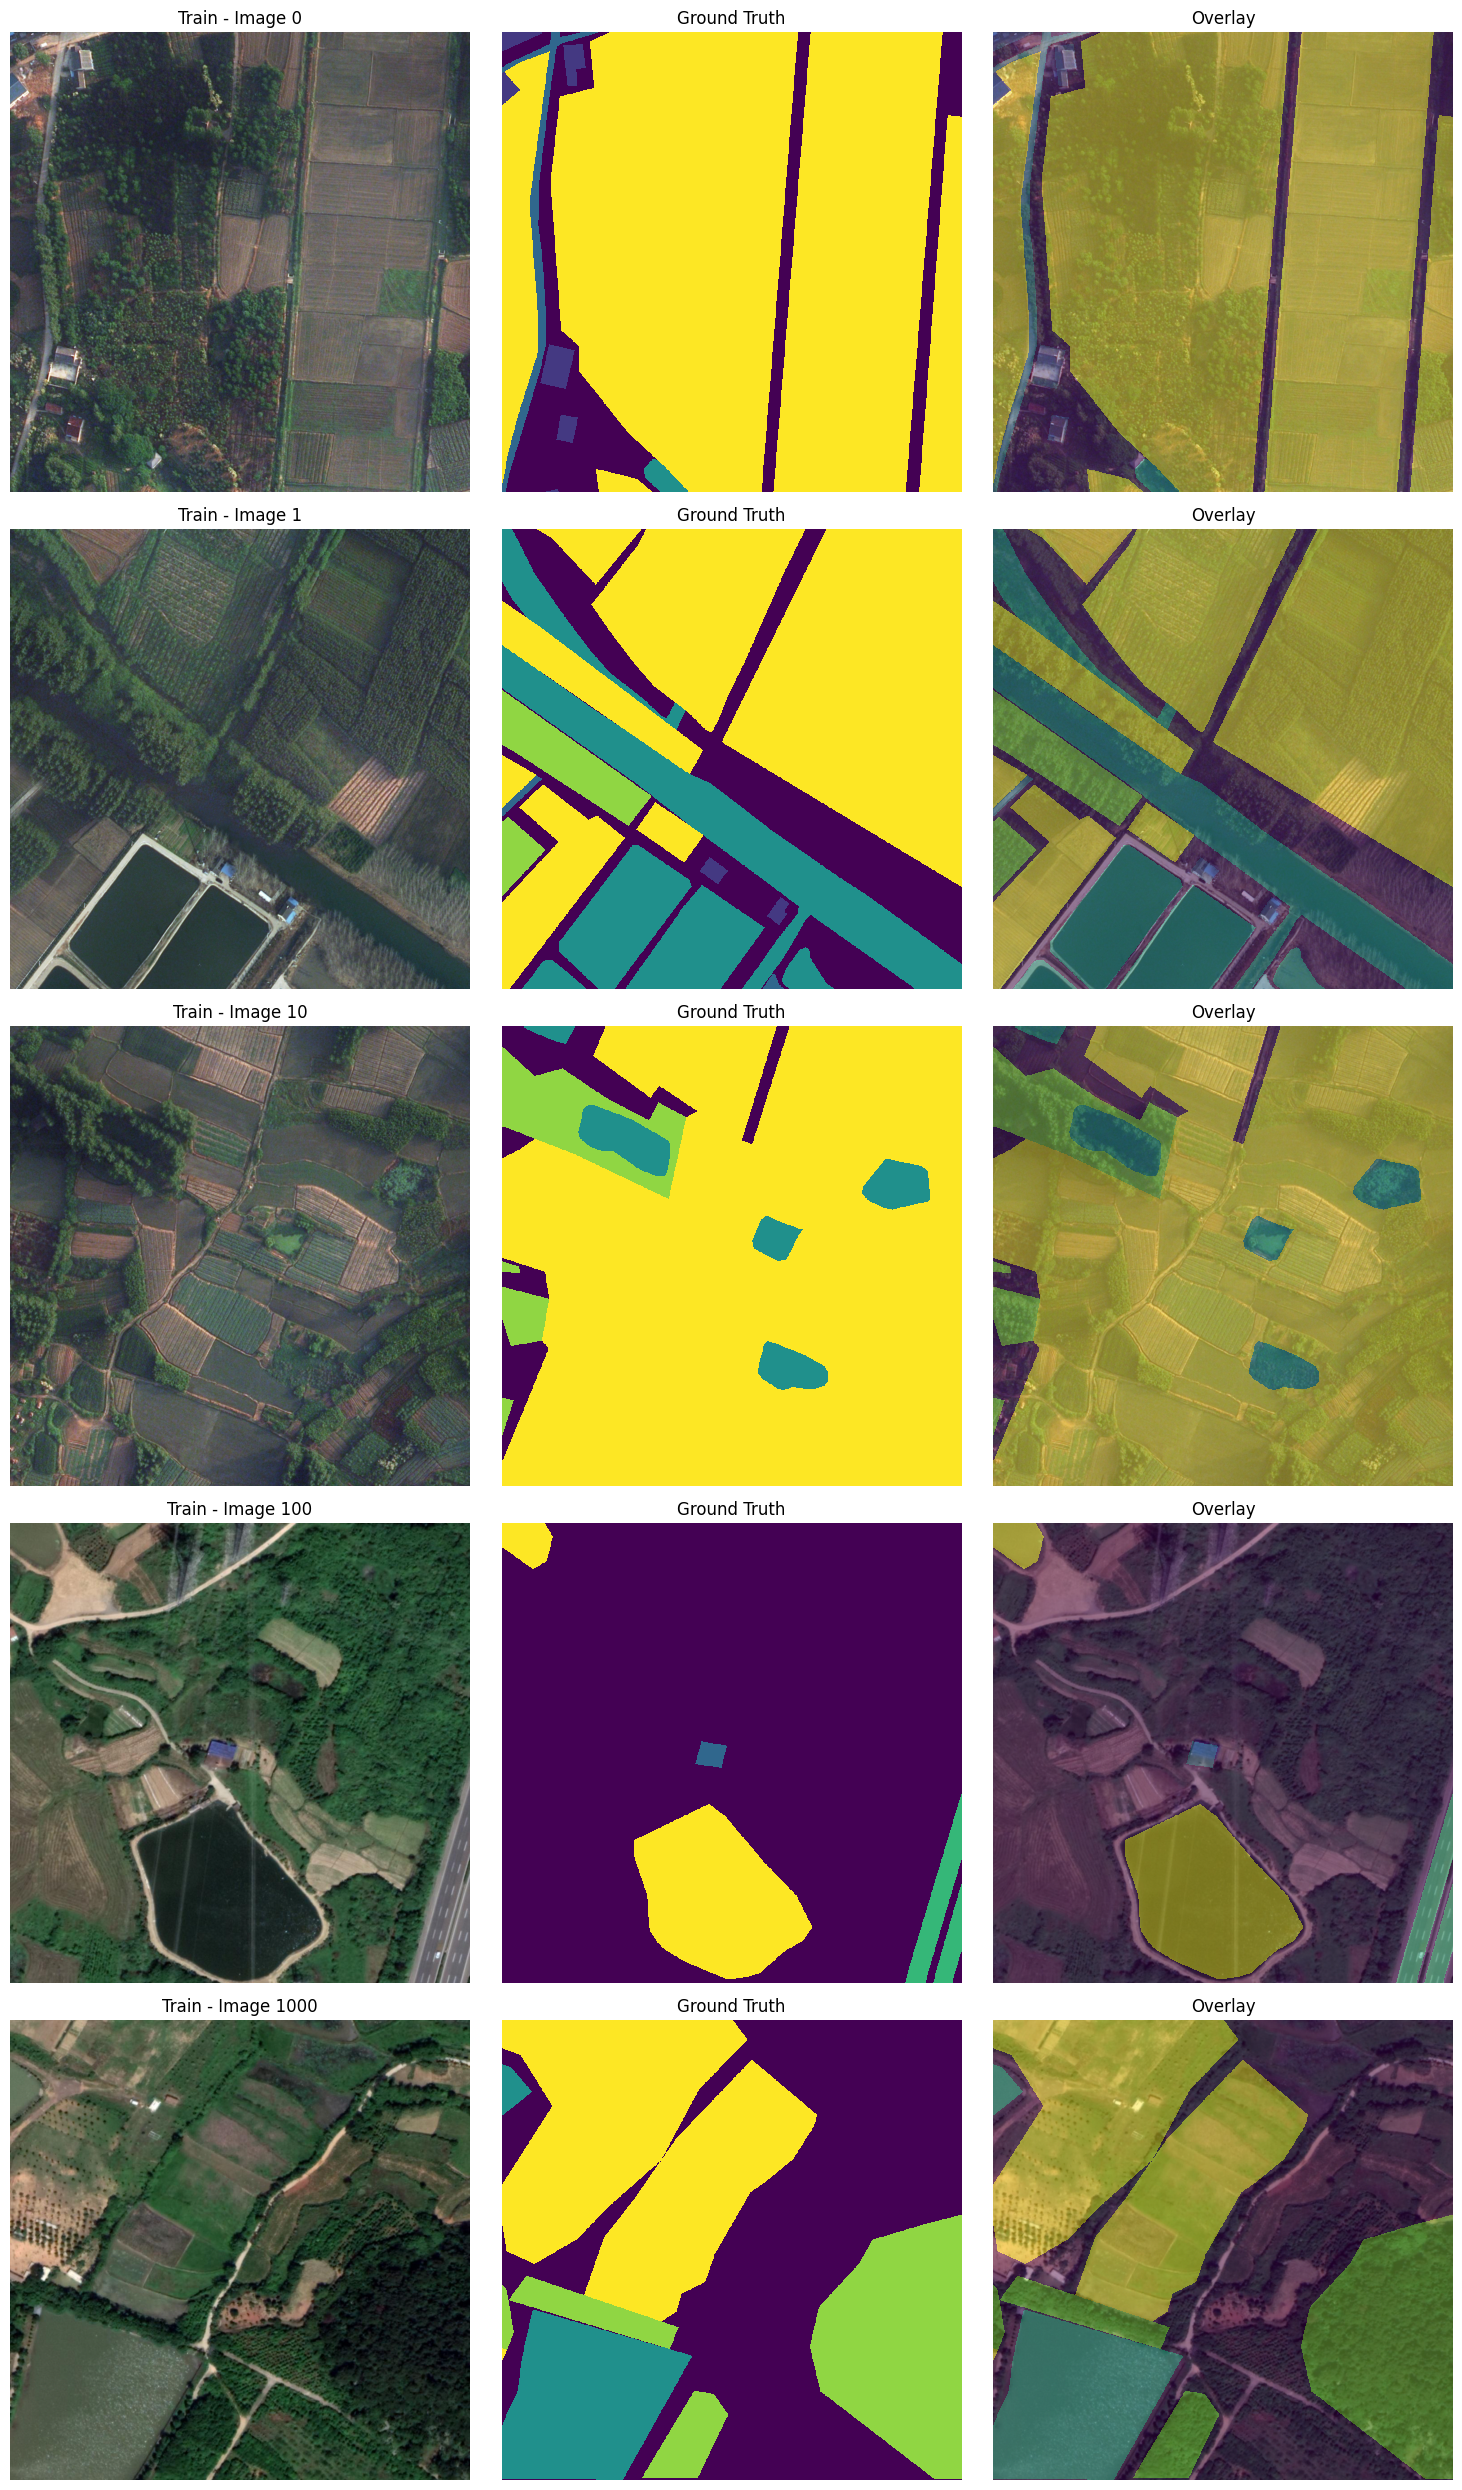

In [11]:
# ============================================================
# 8. VISUALIZE 5 SAMPLES WITH CLASS LEGEND
# ============================================================

sample_pairs = all_pairs[:5]
fig, axes = plt.subplots(len(sample_pairs), 3, figsize=(15, 5 * len(sample_pairs)))
if len(sample_pairs) == 1:
    axes = np.expand_dims(axes, 0)

for r, (name, img_path, msk_path, split) in enumerate(sample_pairs):
    img = np.array(Image.open(img_path).convert("RGB"))
    msk = np.array(Image.open(msk_path))
    axes[r, 0].imshow(img)
    axes[r, 0].set_title(f"{split} - Image {name}")
    axes[r, 0].axis("off")
    axes[r, 1].imshow(msk, interpolation="nearest")
    axes[r, 1].set_title("Ground Truth")
    axes[r, 1].axis("off")
    axes[r, 2].imshow(img)
    axes[r, 2].imshow(msk, alpha=0.45, interpolation="nearest")
    axes[r, 2].set_title("Overlay")
    axes[r, 2].axis("off")

plt.tight_layout()
plt.show()

In [12]:
# ============================================================
# 9. FINAL DATASET SUMMARY
# ============================================================

summary = {
    "Total images": len(train_images) + len(val_images) + len(test_images),
    "Train images": len(train_images),
    "Train masks": len(train_masks),
    "Train matched pairs": len(train_match),
    "Validation images": len(val_images),
    "Validation masks": len(val_masks),
    "Validation matched pairs": len(val_match),
    "Test images": len(test_images),
    "Test masks": len(test_masks),
    "Total supervised pairs": len(train_match) + len(val_match),
    "Image size": "1024 x 1024",
    "Mask size": "1024 x 1024",
    "Corrupted images": len(train_img_corrupt) + len(val_img_corrupt) + len(test_img_corrupt),
    "Corrupted masks": len(train_mask_corrupt) + len(val_mask_corrupt),
    "Train dimension mismatches": len(train_dim_mismatch),
    "Validation dimension mismatches": len(val_dim_mismatch),
    "Raw mask IDs": str(class_ids),
}

summary_df = pd.DataFrame(list(summary.items()), columns=["Check", "Result"])
display(summary_df)

,Check,Result
0,Total images,5987
1,Train images,2522
2,Train masks,2522
3,Train matched pairs,2522
4,Validation images,1669
5,Validation masks,1669
6,Validation matched pairs,1669
7,Test images,1796
8,Test masks,0
9,Total supervised pairs,4191


In [13]:
# ============================================================
# 10. FINAL VERIFICATION STATUS
# ============================================================

checks = {
    "Train images found": len(train_images) > 0,
    "Train masks found": len(train_masks) > 0,
    "All Train images have masks": len(train_img_only) == 0,
    "All Train masks have images": len(train_mask_only) == 0,
    "All Val images have masks": len(val_img_only) == 0,
    "All Val masks have images": len(val_mask_only) == 0,
    "No corrupted images": len(train_img_corrupt) + len(val_img_corrupt) + len(test_img_corrupt) == 0,
    "No corrupted masks": len(train_mask_corrupt) + len(val_mask_corrupt) == 0,
    "No Train dimension mismatches": len(train_dim_mismatch) == 0,
    "No Val dimension mismatches": len(val_dim_mismatch) == 0,
    "Expected 8 raw mask IDs (0-7)": class_ids == list(range(8)),
}

print("=" * 70)
print("LOVE-DA DATASET VERIFICATION")
print("=" * 70)
for check, status in checks.items():
    print(f"{'✓' if status else '✗'} {check}")

print("=" * 70)
if all(checks.values()):
    print("DATASET VERIFICATION PASSED")
    print("Next: preprocessing and train/validation DataLoaders.")
else:
    print("DATASET VERIFICATION NEEDS ATTENTION")
    print("Review the failed checks above before training.")

LOVE-DA DATASET VERIFICATION
✓ Train images found
✓ Train masks found
✓ All Train images have masks
✓ All Train masks have images
✓ All Val images have masks
✓ All Val masks have images
✓ No corrupted images
✓ No corrupted masks
✓ No Train dimension mismatches
✓ No Val dimension mismatches
✓ Expected 8 raw mask IDs (0-7)
DATASET VERIFICATION PASSED
Next: preprocessing and train/validation DataLoaders.


In [14]:
# ============================================================
# 11. SAVE VERIFICATION REPORTS
# ============================================================

REPORT_DIR = DATASET_DIR / "verification_report"
REPORT_DIR.mkdir(exist_ok=True)

summary_df.to_csv(REPORT_DIR / "dataset_summary.csv", index=False)
class_table.to_csv(REPORT_DIR / "class_distribution.csv", index=False)

if train_dim_mismatch:
    pd.DataFrame(train_dim_mismatch).to_csv(REPORT_DIR / "train_dimension_mismatches.csv", index=False)
if val_dim_mismatch:
    pd.DataFrame(val_dim_mismatch).to_csv(REPORT_DIR / "val_dimension_mismatches.csv", index=False)

print("Reports saved to:", REPORT_DIR.resolve())

Reports saved to: C:\Users\CUTM\Desktop\Remote-Sensing-Semantic-Segmentation\LoveDA\verification_report
